# ePC-SAFT Integration Tutorial: Lithium Extraction from Sodium Case Study

The notebook has three goals:

1. Define a representative single-stage lithium extraction from sodium case study,
2. Generate stage-response data from a chemistry evaluator through `epcsaft-pse`, and
3. Train an algebraic surrogate that `PrOMMiS` can use inside a process optimization workflow.

The values used here are simply the nominal basis for the case study. The same workflow can be repeated with a different concentration window, extractant level, or organic-to-aqueous ratio.

## 1. Setup

The first cell locates the local `prommis` and `epcsaft-pse` source trees, imports the packages used in the tutorial, and prints the surrogate feature interface.

The notebook uses package interfaces directly so that each step in the workflow remains visible: chemistry-stage evaluation, surrogate fitting, and process-model integration.

In [1]:
from __future__ import annotations

import sys
from dataclasses import fields
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyomo.environ import Constraint, ConcreteModel, Expression, Param, Set, Var, value
from pyomo.environ import units as pyunits


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'prommis').exists():
            return candidate
    raise RuntimeError('Could not find the prommis repo root from the current working directory.')


repo_root = find_repo_root(Path.cwd())
prommis_src = repo_root / 'src'
epcsaft_pse_src_candidates = [
    repo_root.parent / 'pcsaft-pse' / 'src',
    Path(r'C:/Users/Tanner/Documents/git/pcsaft-pse/src'),
]
epcsaft_pse_src = next((candidate for candidate in epcsaft_pse_src_candidates if candidate.exists()), None)

if str(prommis_src) not in sys.path:
    sys.path.insert(0, str(prommis_src))
if epcsaft_pse_src is None:
    raise RuntimeError('Could not locate epcsaft-pse/src. This tutorial expects the sibling repo to be present.')
if str(epcsaft_pse_src) not in sys.path:
    sys.path.insert(0, str(epcsaft_pse_src))

from idaes.core import (
    Component,
    FlowDirection,
    FlowsheetBlock,
    MaterialFlowBasis,
    Phase,
    PhysicalParameterBlock,
    StateBlock,
    StateBlockData,
    declare_process_block_class,
)
from idaes.core.initialization.block_triangularization import BlockTriangularizationInitializer
from idaes.core.solvers import get_solver
from idaes.core.util.initialization import fix_state_vars
from idaes.core.util.model_statistics import degrees_of_freedom

from epcsaft_pse import PCSAFTBlock, StageInputs, fit_stage_surrogate, evaluate_surrogate, get_overlay_metadata, run_lle_stage
from epcsaft_pse.surrogate import DEFAULT_FEATURES
from prommis.solvent_extraction.solvent_extraction import SolventExtraction

pd.set_option('display.precision', 4)
plt.rcParams['figure.dpi'] = 140

print(f'repo_root = {repo_root}')
print(f'epcsaft_pse_src = {epcsaft_pse_src}')
print(f'surrogate features = {DEFAULT_FEATURES}')

repo_root = C:\Users\Tanner\Documents\git\prommis
epcsaft_pse_src = C:\Users\Tanner\Documents\git\pcsaft-pse\src
surrogate features = ['li_mg_L', 'na_mg_L', 'o_to_a_ratio', 'top_mol_L']


## 2. Define a Representative Single-Stage Basis

The case study uses a single contact stage with:

- an aqueous feed containing lithium, sodium, and chloride,
- an organic phase containing `TOP` in `Hexane`, and
- a specified organic-to-aqueous ratio.

These values are simply the nominal basis for the tutorial. They can be changed later to create new training data or to explore a different operating window.

In [2]:
MW = {
    'Li': 6.94e-3,
    'Na': 22.98976928e-3,
    'Cl': 35.45e-3,
    'TOP': 434.63e-3,
    'Hexane': 86.17848e-3,
}


def mg_L_to_mol_L(value_mg_L: float, species: str) -> float:
    return float(value_mg_L) * 1e-6 / MW[species]


def mol_L_to_mg_L(value_mol_L: float, species: str) -> float:
    return float(value_mol_L) * MW[species] * 1e6


def neutral_cl_mg_L(li_mg_L: float, na_mg_L: float) -> float:
    return mol_L_to_mg_L(
        mg_L_to_mol_L(li_mg_L, 'Li') + mg_L_to_mol_L(na_mg_L, 'Na'),
        'Cl',
    )


def kappa_to_distribution_ratio(kappa: float, o_to_a_ratio: float, eps: float = 1e-8) -> float:
    kappa = max(eps, min(1.0 - eps, float(kappa)))
    oa = max(float(o_to_a_ratio), eps)
    return (kappa / (1.0 - kappa)) / oa


def distribution_ratio_to_kappa(distribution_ratio, o_to_a_ratio, eps: float = 1e-8):
    return (distribution_ratio * o_to_a_ratio) / (1.0 + distribution_ratio * o_to_a_ratio + eps)


basis = {
    'li_mg_L': 60.0,
    'na_mg_L': 10900.0,
    'top_mol_L': 0.015,
    'o_to_a_ratio': 1.0,
    'aq_flow_L_h': 1000.0,
    'hexane_mol_L': 0.6548 / 0.08617848,
}
basis['cl_mg_L'] = neutral_cl_mg_L(basis['li_mg_L'], basis['na_mg_L'])

chemistry_stage_inputs = StageInputs(
    li_mg_L=basis['li_mg_L'],
    na_mg_L=basis['na_mg_L'],
    top_mol_L=basis['top_mol_L'],
    o_to_a_ratio=basis['o_to_a_ratio'],
    stage_model='case_study_selective',
    compute_raw_diagnostics=False,
)

basis_table = pd.DataFrame(
    {
        'Quantity': [
            'Aqueous Li concentration',
            'Aqueous Na concentration',
            'Aqueous Cl concentration',
            'Organic TOP concentration',
            'Organic Hexane concentration',
            'Organic-to-aqueous ratio',
            'Aqueous flowrate',
        ],
        'Value': [
            basis['li_mg_L'],
            basis['na_mg_L'],
            basis['cl_mg_L'],
            basis['top_mol_L'],
            basis['hexane_mol_L'],
            basis['o_to_a_ratio'],
            basis['aq_flow_L_h'],
        ],
        'Units': ['mg/L', 'mg/L', 'mg/L', 'mol/L', 'mol/L', '-', 'L/h'],
    }
)

basis_table

,Quantity,Value,Units
0,Aqueous Li concentration,60.0000,mg/L
1,Aqueous Na concentration,10900.0000,mg/L
2,Aqueous Cl concentration,17114.1778,mg/L
3,Organic TOP concentration,0.0150,mol/L
4,Organic Hexane concentration,7.5982,mol/L
5,Organic-to-aqueous ratio,1.0000,-
6,Aqueous flowrate,1000.0000,L/h



## 3. Inspect the Surrogate Interface and the Main `epcsaft-pse` Methods

This notebook uses a small set of `epcsaft-pse` interfaces:

- `StageInputs` to define the stage conditions,
- `run_lle_stage` to evaluate the stage-response generator,
- `get_overlay_metadata` to inspect the parameter source metadata,
- `fit_stage_surrogate` to regress an algebraic surrogate from sampled stage data,
- `evaluate_surrogate` to query the fitted surrogate outside the process model, and
- `PCSAFTBlock` to embed the surrogate equations into the `PrOMMiS` model.

Users can also provide their own parameter basis through the `StageInputs` object. The main hooks are:

- `parameter_overlay` for a packaged overlay shipped with `epcsaft-pse`,
- `parameter_module_path` when a user wants to point at a custom PC-SAFT parameter file, and
- `kij_overrides` when a small number of binary interaction parameters need to be changed without replacing the whole parameter source.

The next cell summarizes the feature interface used in the tutorial and shows a simple customization example.


In [3]:
feature_table = pd.DataFrame(
    {
        'Input variable': ['li_mg_L', 'na_mg_L', 'o_to_a_ratio', 'top_mol_L'],
        'Meaning': [
            'Aqueous lithium concentration entering the stage',
            'Aqueous sodium concentration entering the stage',
            'Organic-to-aqueous volumetric ratio',
            'Organic TOP concentration',
        ],
        'Nominal value': [
            basis['li_mg_L'],
            basis['na_mg_L'],
            basis['o_to_a_ratio'],
            basis['top_mol_L'],
        ],
        'Units': ['mg/L', 'mg/L', '-', 'mol/L'],
    }
)

method_table = pd.DataFrame(
    {
        'epcsaft-pse method': [
            'StageInputs',
            'run_lle_stage',
            'get_overlay_metadata',
            'fit_stage_surrogate',
            'evaluate_surrogate',
            'PCSAFTBlock',
        ],
        'Role in the workflow': [
            'Collects the process-facing stage inputs',
            'Evaluates the stage-response generator at one operating point',
            'Reports the parameter-source metadata for the case study',
            'Fits the algebraic surrogate from sampled stage data',
            'Evaluates the fitted surrogate outside the process model',
            'Embeds the surrogate equations into the Pyomo/PrOMMiS model',
        ],
    }
)

output_table = pd.DataFrame(
    {
        'Surrogate target': ['D_li', 'D_na', 'D_cl'],
        'Meaning': [
            'Lithium distribution coefficient',
            'Sodium distribution coefficient',
            'Chloride distribution coefficient',
        ],
    }
)

overlay_metadata = get_overlay_metadata(StageInputs().parameter_overlay)
parameter_source_table = pd.DataFrame(
    {
        'Species': list(overlay_metadata['parameter_sources'].keys()),
        'Parameter source': list(overlay_metadata['parameter_sources'].values()),
    }
)

customization_example = """custom_stage = StageInputs(
    li_mg_L=80.0,
    na_mg_L=9500.0,
    top_mol_L=0.020,
    o_to_a_ratio=1.2,
    stage_model='case_study_selective',
    parameter_overlay='my_overlay',
    parameter_module_path=r'C:/path/to/my_epcsaft_properties.py',
    kij_overrides={('Li+', 'TOP'): 0.15},
)"""

display(feature_table)
display(method_table)
display(output_table)
display(parameter_source_table)
print('Example custom StageInputs configuration:')
print(customization_example)

,Input variable,Meaning,Nominal value,Units
0,li_mg_L,Aqueous lithium concentration entering the stage,60.000,mg/L
1,na_mg_L,Aqueous sodium concentration entering the stage,10900.000,mg/L
2,o_to_a_ratio,Organic-to-aqueous volumetric ratio,1.000,-
3,top_mol_L,Organic TOP concentration,0.015,mol/L


,epcsaft-pse method,Role in the workflow
0,StageInputs,Collects the process-facing stage inputs
1,run_lle_stage,Evaluates the stage-response generator at one ...
2,get_overlay_metadata,Reports the parameter-source metadata for the ...
3,fit_stage_surrogate,Fits the algebraic surrogate from sampled stag...
4,evaluate_surrogate,Evaluates the fitted surrogate outside the pro...
5,PCSAFTBlock,Embeds the surrogate equations into the Pyomo/...


,Surrogate target,Meaning
0,D_li,Lithium distribution coefficient
1,D_na,Sodium distribution coefficient
2,D_cl,Chloride distribution coefficient


,Species,Parameter source
0,H2O,Lithium_Extraction.data.epcsaft_properties:H2O...
1,Hexane,Lithium_Extraction.data.epcsaft_properties:Hexane
2,TOP,Lithium_Extraction.data.epcsaft_properties:TOP
3,Li+,Lithium_Extraction.data.epcsaft_properties:Li+
4,Na+,Lithium_Extraction.data.epcsaft_properties:Na+
5,Cl-,Lithium_Extraction.data.epcsaft_properties:Cl-


Example custom StageInputs configuration:
custom_stage = StageInputs(
    li_mg_L=80.0,
    na_mg_L=9500.0,
    top_mol_L=0.020,
    o_to_a_ratio=1.2,
    stage_model='case_study_selective',
    parameter_overlay='my_overlay',
    parameter_module_path=r'C:/path/to/my_epcsaft_properties.py',
    kij_overrides={('Li+', 'TOP'): 0.15},
)



## 4. Sample One Detailed Stage Point

This cell evaluates the parameterized stage-response generator once at the nominal case-study point.

The returned values are the output of `run_lle_stage(...)` for that operating point. In Step 5, the notebook samples
many such points over the design window and fits a surrogate from the resulting dataset.

For the integrated stage model, the surrogate targets are the three distribution coefficients. The single-point results shown here are therefore reference data and a nominal check, not fixed coefficients that the `PrOMMiS` model is forced to copy.


In [ ]:
chemistry_stage = run_lle_stage(chemistry_stage_inputs)

chemistry_distribution = {
    'D_li': chemistry_stage.D_li,
    'D_na': kappa_to_distribution_ratio(chemistry_stage.kappa_na, basis['o_to_a_ratio']),
    'D_cl': kappa_to_distribution_ratio(chemistry_stage.kappa_cl, basis['o_to_a_ratio']),
}

chemistry_summary = pd.DataFrame(
    {
        'Metric': [
            'Evaluator mode',
            'Li extraction (%)',
            'Na extraction (%)',
            'D_li',
            'D_na',
            'D_cl',
            'kappa_li',
            'kappa_na',
            'kappa_cl',
            'Li/Na selectivity (-)',
        ],
        'Value': [
            chemistry_stage.diagnostics.get('stage_model'),
            chemistry_stage.eta_li_pct,
            chemistry_stage.eta_na_pct,
            chemistry_distribution['D_li'],
            chemistry_distribution['D_na'],
            chemistry_distribution['D_cl'],
            chemistry_stage.kappa_li,
            chemistry_stage.kappa_na,
            chemistry_stage.kappa_cl,
            chemistry_stage.li_na_selectivity,
        ],
    }
)

chemistry_streams = pd.DataFrame(
    {
        'Species': ['Li+', 'Na+', 'Cl-'],
        'Aqueous outlet (mol/L)': [
            chemistry_stage.aqueous_out_mol_L['Li+'],
            chemistry_stage.aqueous_out_mol_L['Na+'],
            chemistry_stage.aqueous_out_mol_L['Cl-'],
        ],
        'Organic outlet (mol/L)': [
            chemistry_stage.organic_out_mol_L['Li+'],
            chemistry_stage.organic_out_mol_L['Na+'],
            chemistry_stage.organic_out_mol_L['Cl-'],
        ],
    }
)

display(chemistry_summary)
display(chemistry_streams)


## 5. Generate Training Data and Fit a Multi-Output Surrogate

A surrogate becomes useful when the stage-response generator is sampled over a local design window around the operating region of interest instead of at only one point.

In this notebook, `fit_stage_surrogate` fits a standardized quadratic polynomial with linear, squared, and pairwise cross terms using regularized least-squares regression. The targets are the three distribution coefficients used later by the process model: $D_{Li}$, $D_{Na}$, and $D_{Cl}$.

That means the embedded model is an explicit algebraic response surface trained for a declared operating window. It is not a table lookup and it is not a direct copy of the nominal stage outputs.


In [5]:

design_space = {
    'li_mg_L': np.linspace(52.0, 68.0, 5),
    'na_mg_L': np.linspace(10200.0, 11600.0, 5),
    'o_to_a_ratio': np.linspace(0.85, 1.15, 5),
    'top_mol_L': np.linspace(0.0135, 0.0165, 5),
}

training_rows = []
for li_mg_L, na_mg_L, o_to_a_ratio, top_mol_L in product(
    design_space['li_mg_L'],
    design_space['na_mg_L'],
    design_space['o_to_a_ratio'],
    design_space['top_mol_L'],
):
    out = run_lle_stage(
        StageInputs(
            li_mg_L=float(li_mg_L),
            na_mg_L=float(na_mg_L),
            top_mol_L=float(top_mol_L),
            o_to_a_ratio=float(o_to_a_ratio),
            stage_model='case_study_selective',
            compute_raw_diagnostics=False,
        )
    )
    training_rows.append(
        {
            'li_mg_L': float(li_mg_L),
            'na_mg_L': float(na_mg_L),
            'o_to_a_ratio': float(o_to_a_ratio),
            'top_mol_L': float(top_mol_L),
            'D_li': out.D_li,
            'D_na': kappa_to_distribution_ratio(out.kappa_na, o_to_a_ratio),
            'D_cl': kappa_to_distribution_ratio(out.kappa_cl, o_to_a_ratio),
            'kappa_li': out.kappa_li,
            'kappa_na': out.kappa_na,
            'kappa_cl': out.kappa_cl,
            'eta_li_pct': out.eta_li_pct,
        }
    )

training_df = pd.DataFrame(training_rows)
surrogate_model = fit_stage_surrogate(
    training_df,
    config={
        'target_config': {
            'D_li': {'transform': 'identity'},
            'D_na': {'transform': 'identity'},
            'D_cl': {'transform': 'identity'},
        }
    },
)
nominal_surrogate = evaluate_surrogate(
    {
        'li_mg_L': basis['li_mg_L'],
        'na_mg_L': basis['na_mg_L'],
        'o_to_a_ratio': basis['o_to_a_ratio'],
        'top_mol_L': basis['top_mol_L'],
    },
    surrogate_model,
)

fit_metrics = pd.DataFrame(
    [
        {
            'Target': target.name,
            'RMSE': target.fit_metrics['rmse'],
            'MAE': target.fit_metrics['mae'],
            'Max abs': target.fit_metrics['max_abs'],
        }
        for target in surrogate_model.targets
    ]
)

surrogate_structure = pd.DataFrame(
    {
        'Item': [
            'Surrogate family',
            'Feature variables',
            'Target variables',
            'Basis terms',
            'Fitting method',
            'Training samples',
        ],
        'Value': [
            'Quadratic polynomial response surface',
            'li_mg_L, na_mg_L, o_to_a_ratio, top_mol_L',
            'D_li, D_na, D_cl',
            'Intercept + linear + squared + pairwise cross terms',
            'Regularized least-squares regression',
            len(training_df),
        ],
    }
)

nominal_check = pd.DataFrame(
    {
        'Target': ['D_li', 'D_na', 'D_cl'],
        'Detailed stage value': [chemistry_distribution['D_li'], chemistry_distribution['D_na'], chemistry_distribution['D_cl']],
        'Surrogate value': [nominal_surrogate['D_li'], nominal_surrogate['D_na'], nominal_surrogate['D_cl']],
    }
)

display(surrogate_structure)
display(training_df.head(8))
display(fit_metrics)
display(nominal_check)


,Item,Value
0,Surrogate family,Quadratic polynomial response surface
1,Feature variables,"li_mg_L, na_mg_L, o_to_a_ratio, top_mol_L"
2,Target variables,"D_li, D_na, D_cl"
3,Basis terms,Intercept + linear + squared + pairwise cross ...
4,Fitting method,Regularized least-squares regression
5,Training samples,625


,li_mg_L,na_mg_L,o_to_a_ratio,top_mol_L,D_li,D_na,D_cl,kappa_li,kappa_na,kappa_cl,eta_li_pct
0,52.0,10200.0,0.850,0.0135,0.7361,0.0093,0.0176,0.4240,0.0078,0.0147,42.3997
1,52.0,10200.0,0.850,0.0143,0.8101,0.0098,0.0186,0.4476,0.0082,0.0155,44.7553
2,52.0,10200.0,0.850,0.0150,0.8907,0.0103,0.0196,0.4711,0.0087,0.0163,47.1108
3,52.0,10200.0,0.850,0.0158,0.9789,0.0108,0.0205,0.4947,0.0091,0.0172,49.4664
4,52.0,10200.0,0.850,0.0165,1.0756,0.0113,0.0215,0.5182,0.0095,0.0180,51.8219
5,52.0,10200.0,0.925,0.0135,0.8567,0.0093,0.0176,0.4614,0.0085,0.0160,46.1409
6,52.0,10200.0,0.925,0.0143,0.9495,0.0098,0.0186,0.4870,0.0090,0.0169,48.7043
7,52.0,10200.0,0.925,0.0150,1.0520,0.0103,0.0196,0.5127,0.0094,0.0178,51.2677


,Target,RMSE,MAE,Max abs
0,D_li,2.0863e-02,1.4883e-02,1.2964e-01
1,D_na,1.9914e-06,1.3478e-06,1.0159e-05
2,D_cl,2.2949e-06,1.8659e-06,7.3246e-06


,Target,Detailed stage value,Surrogate value
0,D_li,1.0835,1.0789
1,D_na,0.0092,0.0092
2,D_cl,0.0186,0.0186


## 6. Check Response with One Process Variable

Before embedding the surrogate in the process model, it is useful to confirm that the surrogate follows the stage-response trend for a single decision variable.

Here the variable of interest is $O/A$. The solid lines come from the sampled stage-response model and the dashed lines come from the fitted surrogate. Because the surrogate is trained on distribution coefficients, those are the quantities shown in the plot.

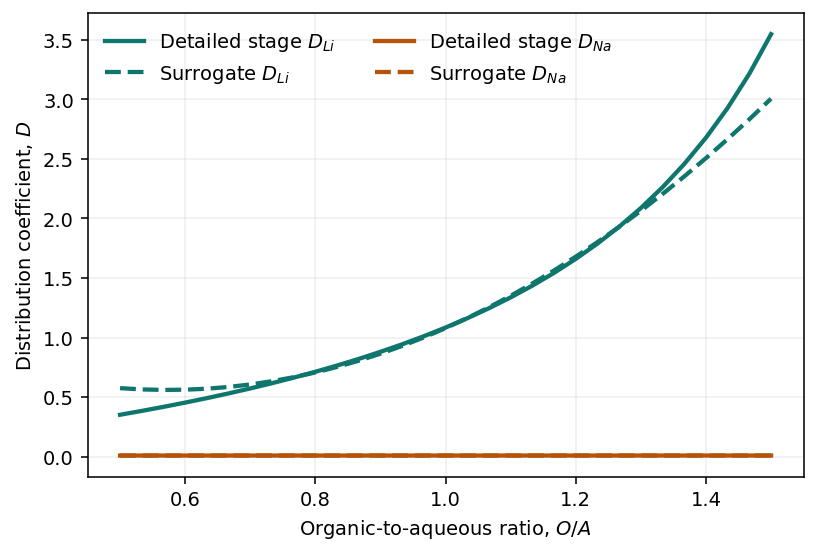

In [6]:
oa_grid = np.linspace(0.5, 1.5, 31)
live_rows = []
surrogate_rows = []
for oa in oa_grid:
    live = run_lle_stage(
        StageInputs(
            li_mg_L=basis['li_mg_L'],
            na_mg_L=basis['na_mg_L'],
            top_mol_L=basis['top_mol_L'],
            o_to_a_ratio=float(oa),
            stage_model='case_study_selective',
            compute_raw_diagnostics=False,
        )
    )
    pred = evaluate_surrogate(
        {
            'li_mg_L': basis['li_mg_L'],
            'na_mg_L': basis['na_mg_L'],
            'o_to_a_ratio': float(oa),
            'top_mol_L': basis['top_mol_L'],
        },
        surrogate_model,
    )
    live_rows.append(
        {
            'o_to_a_ratio': oa,
            'D_li': live.D_li,
            'D_na': kappa_to_distribution_ratio(live.kappa_na, oa),
        }
    )
    surrogate_rows.append({'o_to_a_ratio': oa, 'D_li': pred['D_li'], 'D_na': pred['D_na']})

live_df = pd.DataFrame(live_rows)
surrogate_df = pd.DataFrame(surrogate_rows)

fig, ax = plt.subplots(figsize=(6.6, 4.3))
ax.plot(live_df['o_to_a_ratio'], live_df['D_li'], color='#0f766e', linewidth=2.2, label='Detailed stage $D_{Li}$')
ax.plot(surrogate_df['o_to_a_ratio'], surrogate_df['D_li'], color='#0f766e', linestyle='--', linewidth=2.2, label='Surrogate $D_{Li}$')
ax.plot(live_df['o_to_a_ratio'], live_df['D_na'], color='#b45309', linewidth=2.2, label='Detailed stage $D_{Na}$')
ax.plot(surrogate_df['o_to_a_ratio'], surrogate_df['D_na'], color='#b45309', linestyle='--', linewidth=2.2, label='Surrogate $D_{Na}$')
ax.set_xlabel('Organic-to-aqueous ratio, $O/A$')
ax.set_ylabel('Distribution coefficient, $D$')
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=2)
plt.show()

## 7. Define the PrOMMiS State Models Used by the Stage

The next cell defines small local aqueous and organic property packages for the single-stage tutorial model. They are written in the notebook so the coupling remains visible.


In [7]:
@declare_process_block_class('NotebookLiNaClAqParameters')
class NotebookLiNaClAqParameterData(PhysicalParameterBlock):
    def build(self):
        super().build()

        self.liquid = Phase()
        self.H2O = Component()
        self.Li = Component()
        self.Na = Component()
        self.Cl = Component()

        self.dissolved_elements = Set(initialize=['Li', 'Na', 'Cl'])

        self.mw = Param(
            self.component_list,
            units=pyunits.kg / pyunits.mol,
            initialize={
                'H2O': 18.015e-3,
                'Li': MW['Li'],
                'Na': MW['Na'],
                'Cl': MW['Cl'],
            },
        )
        self.dens_mass = Param(
            initialize=1.0,
            units=pyunits.kg / pyunits.litre,
            mutable=True,
        )
        self._state_block_class = NotebookLiNaClAqStateBlock

    @classmethod
    def define_metadata(cls, obj):
        obj.add_default_units(
            {
                'time': pyunits.hour,
                'mass': pyunits.kg,
                'amount': pyunits.mol,
                'length': pyunits.m,
                'temperature': pyunits.K,
            }
        )


class _NotebookLiNaClAqStateBlock(StateBlock):
    def fix_initialization_states(self):
        fix_state_vars(self)


@declare_process_block_class(
    'NotebookLiNaClAqStateBlock',
    block_class=_NotebookLiNaClAqStateBlock,
)
class NotebookLiNaClAqStateBlockData(StateBlockData):
    def build(self):
        super().build()

        self.conc_mass_comp = Var(
            self.params.dissolved_elements,
            units=pyunits.mg / pyunits.litre,
            bounds=(1e-20, None),
        )
        self.flow_vol = Var(units=pyunits.litre / pyunits.hour, bounds=(1e-8, None))
        self.conc_mol_comp = Var(
            self.params.dissolved_elements,
            units=pyunits.mol / pyunits.litre,
            initialize=1e-5,
            bounds=(1e-20, None),
        )

        @self.Constraint(self.params.dissolved_elements)
        def molar_concentration_constraint(b, j):
            return pyunits.convert(
                b.conc_mol_comp[j] * b.params.mw[j],
                to_units=pyunits.mg / pyunits.litre,
            ) == b.conc_mass_comp[j]

    def get_material_flow_basis(self):
        return MaterialFlowBasis.molar

    def get_material_flow_terms(self, p, j):
        if j == 'H2O':
            return self.flow_vol * self.params.dens_mass / self.params.mw[j]
        return pyunits.convert(
            self.flow_vol * self.conc_mass_comp[j] / self.params.mw[j],
            to_units=pyunits.mol / pyunits.hour,
        )

    def get_material_density_terms(self, p, j):
        if j == 'H2O':
            return pyunits.convert(
                self.params.dens_mass / self.params.mw[j],
                to_units=pyunits.mol / pyunits.m**3,
            )
        return pyunits.convert(
            self.conc_mass_comp[j] / self.params.mw[j],
            to_units=pyunits.mol / pyunits.m**3,
        )

    def define_state_vars(self):
        return {'flow_vol': self.flow_vol, 'conc_mass_comp': self.conc_mass_comp}


@declare_process_block_class('NotebookLiNaClOgParameters')
class NotebookLiNaClOgParameterData(PhysicalParameterBlock):
    def build(self):
        super().build()

        self.liquid = Phase()
        self.TOP = Component()
        self.Hexane = Component()
        self.Li = Component()
        self.Na = Component()
        self.Cl = Component()

        self.concentration_elements = Set(
            initialize=['TOP', 'Hexane', 'Li', 'Na', 'Cl']
        )

        self.mw = Param(
            self.component_list,
            units=pyunits.kg / pyunits.mol,
            initialize={
                'TOP': MW['TOP'],
                'Hexane': MW['Hexane'],
                'Li': MW['Li'],
                'Na': MW['Na'],
                'Cl': MW['Cl'],
            },
        )
        self._state_block_class = NotebookLiNaClOgStateBlock

    @classmethod
    def define_metadata(cls, obj):
        obj.add_default_units(
            {
                'time': pyunits.hour,
                'mass': pyunits.kg,
                'amount': pyunits.mol,
                'length': pyunits.m,
                'temperature': pyunits.K,
            }
        )


class _NotebookLiNaClOgStateBlock(StateBlock):
    def fix_initialization_states(self):
        fix_state_vars(self)


@declare_process_block_class(
    'NotebookLiNaClOgStateBlock',
    block_class=_NotebookLiNaClOgStateBlock,
)
class NotebookLiNaClOgStateBlockData(StateBlockData):
    def build(self):
        super().build()

        self.conc_mass_comp = Var(
            self.params.concentration_elements,
            units=pyunits.mg / pyunits.litre,
            initialize=1e-7,
            bounds=(1e-20, None),
        )
        self.flow_vol = Var(units=pyunits.litre / pyunits.hour, bounds=(1e-8, None))
        self.conc_mol_comp = Var(
            self.params.concentration_elements,
            units=pyunits.mol / pyunits.litre,
            initialize=1e-5,
            bounds=(1e-20, None),
        )

        @self.Constraint(self.params.concentration_elements)
        def molar_concentration_constraint(b, j):
            return pyunits.convert(
                b.conc_mol_comp[j] * b.params.mw[j],
                to_units=pyunits.mg / pyunits.litre,
            ) == b.conc_mass_comp[j]

    def get_material_flow_basis(self):
        return MaterialFlowBasis.molar

    def get_material_flow_terms(self, p, j):
        return pyunits.convert(
            self.flow_vol * self.conc_mass_comp[j] / self.params.mw[j],
            to_units=pyunits.mol / pyunits.hour,
        )

    def get_material_density_terms(self, p, j):
        return pyunits.convert(
            self.conc_mass_comp[j] / self.params.mw[j],
            to_units=pyunits.mol / pyunits.m**3,
        )

    def define_state_vars(self):
        return {'flow_vol': self.flow_vol, 'conc_mass_comp': self.conc_mass_comp}


print('Local aqueous and organic property packages are defined.')


Local aqueous and organic property packages are defined.



## 8. Build the One-Stage PrOMMiS Model

The next cell builds a one-stage `PrOMMiS` solvent extraction model and connects the surrogate explicitly.

In this version of the tutorial, the surrogate targets are the stage distribution coefficients. The process model then converts those coefficients into transfer fractions through

$$
\kappa_i = \frac{D_i (O/A)}{1 + D_i (O/A)}
$$

This is useful because distribution coefficients are a familiar solvent-extraction quantity, while the `MSContactor` stage equations need a transfer fraction. The process model therefore receives $D_i$ from the surrogate and computes the corresponding stage transfer internally.


In [8]:
def build_single_stage_model(basis: dict[str, float], surrogate_model):
    m = ConcreteModel()
    m.fs = FlowsheetBlock(dynamic=False)
    m.fs.prop_aq = NotebookLiNaClAqParameters()
    m.fs.prop_og = NotebookLiNaClOgParameters()

    m.fs.solex = SolventExtraction(
        number_of_finite_elements=1,
        dynamic=False,
        aqueous_stream={
            'property_package': m.fs.prop_aq,
            'flow_direction': FlowDirection.forward,
            'has_energy_balance': False,
            'has_pressure_balance': False,
        },
        organic_stream={
            'property_package': m.fs.prop_og,
            'flow_direction': FlowDirection.forward,
            'has_energy_balance': False,
            'has_pressure_balance': False,
        },
        aqueous_to_organic=True,
    )

    stage = m.fs.solex.mscontactor.elements.first()

    aq_in = m.fs.solex.mscontactor.aqueous_inlet_state[0]
    aq_in.conc_mass_comp['Li'].fix(basis['li_mg_L'])
    aq_in.conc_mass_comp['Na'].fix(basis['na_mg_L'])
    aq_in.conc_mass_comp['Cl'].fix(basis['cl_mg_L'])
    aq_in.flow_vol.fix(basis['aq_flow_L_h'])

    og_in = m.fs.solex.mscontactor.organic_inlet_state[0]
    og_in.conc_mass_comp['TOP'].fix(mol_L_to_mg_L(basis['top_mol_L'], 'TOP'))
    og_in.conc_mass_comp['Hexane'].fix(mol_L_to_mg_L(basis['hexane_mol_L'], 'Hexane'))
    og_in.conc_mass_comp['Li'].fix(1e-9)
    og_in.conc_mass_comp['Na'].fix(1e-9)
    og_in.conc_mass_comp['Cl'].fix(1e-9)
    og_in.flow_vol.fix(basis['aq_flow_L_h'] * basis['o_to_a_ratio'])

    m.fs.solex.mscontactor.organic[0, stage].flow_vol.fix(value(og_in.flow_vol))

    m.fs.D_li = Var(initialize=chemistry_distribution['D_li'], bounds=(0.0, None))
    m.fs.D_na = Var(initialize=chemistry_distribution['D_na'], bounds=(0.0, None))
    m.fs.D_cl = Var(initialize=chemistry_distribution['D_cl'], bounds=(0.0, None))

    m.fs.o_to_a_ratio = Var(initialize=basis['o_to_a_ratio'], bounds=(0.1, None))
    m.fs.o_to_a_ratio_constraint = Constraint(expr=m.fs.o_to_a_ratio == og_in.flow_vol / aq_in.flow_vol)
    m.fs.top_mol_L = Expression(
        expr=pyunits.convert(og_in.conc_mass_comp['TOP'] / m.fs.prop_og.mw['TOP'], to_units=pyunits.mol / pyunits.litre)
    )

    m.fs.k_li = Expression(expr=distribution_ratio_to_kappa(m.fs.D_li, m.fs.o_to_a_ratio))
    m.fs.k_na = Expression(expr=distribution_ratio_to_kappa(m.fs.D_na, m.fs.o_to_a_ratio))
    m.fs.k_cl = Expression(expr=distribution_ratio_to_kappa(m.fs.D_cl, m.fs.o_to_a_ratio))

    m.fs.pcsaft = PCSAFTBlock(
        aqueous_phase={'composition': {'Li+': aq_in.conc_mass_comp['Li'], 'Na+': aq_in.conc_mass_comp['Na']}},
        organic_phase={'composition': {'TOP': m.fs.top_mol_L}},
        system_state={'o_to_a_ratio': m.fs.o_to_a_ratio},
        target_vars={
            'D_li': m.fs.D_li,
            'D_na': m.fs.D_na,
            'D_cl': m.fs.D_cl,
        },
        mode='surrogate',
        surrogate_model=surrogate_model,
    )

    for t in m.fs.time:
        m.fs.solex.mass_transfer_constraint[t, stage, 'aqueous', 'organic', 'Li'].deactivate()
        m.fs.solex.mass_transfer_constraint[t, stage, 'aqueous', 'organic', 'Na'].deactivate()
        m.fs.solex.mass_transfer_constraint[t, stage, 'aqueous', 'organic', 'Cl'].deactivate()

    @m.fs.Constraint(m.fs.time)
    def li_mass_transfer_constraint(b, t):
        return (
            b.solex.mscontactor.material_transfer_term[t, stage, ('aqueous', 'organic', 'Li')]
            == -b.solex.mscontactor.aqueous_inlet_state[t].get_material_flow_terms(
                b.solex.mscontactor.aqueous.phase_list,
                'Li',
            )
            * b.k_li
        )

    @m.fs.Constraint(m.fs.time)
    def na_mass_transfer_constraint(b, t):
        return (
            b.solex.mscontactor.material_transfer_term[t, stage, ('aqueous', 'organic', 'Na')]
            == -b.solex.mscontactor.aqueous_inlet_state[t].get_material_flow_terms(
                b.solex.mscontactor.aqueous.phase_list,
                'Na',
            )
            * b.k_na
        )

    @m.fs.Constraint(m.fs.time)
    def cl_mass_transfer_constraint(b, t):
        return (
            b.solex.mscontactor.material_transfer_term[t, stage, ('aqueous', 'organic', 'Cl')]
            == -b.solex.mscontactor.aqueous_inlet_state[t].get_material_flow_terms(
                b.solex.mscontactor.aqueous.phase_list,
                'Cl',
            )
            * b.k_cl
        )

    return m


def safe_value(x):
    try:
        return value(x)
    except Exception:
        return np.nan


def summarize_stage_model(m):
    stage = m.fs.solex.mscontactor.elements.first()
    aq_in = m.fs.solex.mscontactor.aqueous_inlet_state[0]
    aq_out = m.fs.solex.mscontactor.aqueous[0, stage]
    og_out = m.fs.solex.mscontactor.organic[0, stage]

    metrics = pd.DataFrame(
        {
            'Metric': [
                'Degrees of freedom',
                'D_li',
                'D_na',
                'D_cl',
                'kappa_li',
                'kappa_na',
                'kappa_cl',
            ],
            'Value': [
                degrees_of_freedom(m),
                value(m.fs.D_li),
                value(m.fs.D_na),
                value(m.fs.D_cl),
                value(m.fs.k_li),
                value(m.fs.k_na),
                value(m.fs.k_cl),
            ],
        }
    )

    streams = pd.DataFrame(
        {
            'Species': ['Li', 'Na', 'Cl', 'TOP', 'Hexane'],
            'Aqueous inlet (mg/L)': [
                safe_value(aq_in.conc_mass_comp['Li']),
                safe_value(aq_in.conc_mass_comp['Na']),
                safe_value(aq_in.conc_mass_comp['Cl']),
                np.nan,
                np.nan,
            ],
            'Aqueous outlet (mg/L)': [
                safe_value(aq_out.conc_mass_comp['Li']),
                safe_value(aq_out.conc_mass_comp['Na']),
                safe_value(aq_out.conc_mass_comp['Cl']),
                np.nan,
                np.nan,
            ],
            'Organic outlet (mg/L)': [
                safe_value(og_out.conc_mass_comp['Li']),
                safe_value(og_out.conc_mass_comp['Na']),
                safe_value(og_out.conc_mass_comp['Cl']),
                safe_value(og_out.conc_mass_comp['TOP']),
                safe_value(og_out.conc_mass_comp['Hexane']),
            ],
        }
    )
    return metrics, streams


model = build_single_stage_model(basis, surrogate_model)
metrics_before_solve, streams_before_solve = summarize_stage_model(model)

display(metrics_before_solve)
display(streams_before_solve)

ERROR: evaluating object as numeric value:
fs.solex.mscontactor.aqueous[0.0,1].conc_mass_comp[Li]
        (object: <class 'pyomo.core.base.var.VarData'>)
    No value for uninitialized VarData object
    fs.solex.mscontactor.aqueous[0.0,1].conc_mass_comp[Li]


ERROR: evaluating object as numeric value:
fs.solex.mscontactor.aqueous[0.0,1].conc_mass_comp[Na]
        (object: <class 'pyomo.core.base.var.VarData'>)
    No value for uninitialized VarData object
    fs.solex.mscontactor.aqueous[0.0,1].conc_mass_comp[Na]


ERROR: evaluating object as numeric value:
fs.solex.mscontactor.aqueous[0.0,1].conc_mass_comp[Cl]
        (object: <class 'pyomo.core.base.var.VarData'>)
    No value for uninitialized VarData object
    fs.solex.mscontactor.aqueous[0.0,1].conc_mass_comp[Cl]


,Metric,Value
0,Degrees of freedom,0.0000
1,D_li,1.0835
2,D_na,0.0092
3,D_cl,0.0186
4,kappa_li,0.5200
5,kappa_na,0.0091
6,kappa_cl,0.0182


,Species,Aqueous inlet (mg/L),Aqueous outlet (mg/L),Organic outlet (mg/L)
0,Li,60.0000,NaN,1.0000e-07
1,Na,10900.0000,NaN,1.0000e-07
2,Cl,17114.1778,NaN,1.0000e-07
3,TOP,NaN,NaN,1.0000e-07
4,Hexane,NaN,NaN,1.0000e-07



## 9. Solve the Integrated Stage Model

When `solve` is called, `PrOMMiS` is solving for the single-stage outlet states and transfer terms that satisfy:

- the inlet conditions fixed above,
- the `SolventExtraction` mass-balance equations,
- the surrogate equations for $D_{Li}$, $D_{Na}$, and $D_{Cl}$,
- the conversion from distribution coefficient to transfer fraction, and
- the custom mass-transfer constraints for lithium, sodium, and chloride.

So the solve is not copying outlet values from the sampled stage object. It is solving for the aqueous and organic outlet concentrations, together with the interphase transfer terms, that are consistent with the surrogate-predicted coefficients and the stage balances.


In [9]:
dof = degrees_of_freedom(model)
assert dof == 0, f'Expected 0 degrees of freedom, found {dof}'

initializer = BlockTriangularizationInitializer(constraint_tolerance=1e-6)
initializer.initialize(model)
results = get_solver().solve(model, tee=False)

metrics_after_solve, streams_after_solve = summarize_stage_model(model)
stage = model.fs.solex.mscontactor.elements.first()
comparison = pd.DataFrame(
    {
        'Metric': [
            'D_li',
            'D_na',
            'D_cl',
            'kappa_li',
            'kappa_na',
            'kappa_cl',
            'Aqueous outlet Li (mg/L)',
            'Aqueous outlet Na (mg/L)',
            'Aqueous outlet Cl (mg/L)',
        ],
        'Detailed stage': [
            chemistry_distribution['D_li'],
            chemistry_distribution['D_na'],
            chemistry_distribution['D_cl'],
            chemistry_stage.kappa_li,
            chemistry_stage.kappa_na,
            chemistry_stage.kappa_cl,
            mol_L_to_mg_L(chemistry_stage.aqueous_out_mol_L['Li+'], 'Li'),
            mol_L_to_mg_L(chemistry_stage.aqueous_out_mol_L['Na+'], 'Na'),
            mol_L_to_mg_L(chemistry_stage.aqueous_out_mol_L['Cl-'], 'Cl'),
        ],
        'Integrated PrOMMiS stage': [
            value(model.fs.D_li),
            value(model.fs.D_na),
            value(model.fs.D_cl),
            value(model.fs.k_li),
            value(model.fs.k_na),
            value(model.fs.k_cl),
            value(model.fs.solex.mscontactor.aqueous[0, stage].conc_mass_comp['Li']),
            value(model.fs.solex.mscontactor.aqueous[0, stage].conc_mass_comp['Na']),
            value(model.fs.solex.mscontactor.aqueous[0, stage].conc_mass_comp['Cl']),
        ],
    }
)

print(results.solver.termination_condition)
display(metrics_after_solve)
display(streams_after_solve)
display(comparison)

optimal


,Metric,Value
0,Degrees of freedom,0.0000
1,D_li,1.0789
2,D_na,0.0092
3,D_cl,0.0186
4,kappa_li,0.5190
5,kappa_na,0.0091
6,kappa_cl,0.0182


,Species,Aqueous inlet (mg/L),Aqueous outlet (mg/L),Organic outlet (mg/L)
0,Li,60.0000,28.8620,31.1380
1,Na,10900.0000,10801.1652,98.8348
2,Cl,17114.1778,16802.3887,311.7892
3,TOP,NaN,NaN,6519.4500
4,Hexane,NaN,NaN,654800.0000


,Metric,Detailed stage,Integrated PrOMMiS stage
0,D_li,1.0835,1.0789
1,D_na,0.0092,0.0092
2,D_cl,0.0186,0.0186
3,kappa_li,0.5200,0.5190
4,kappa_na,0.0091,0.0091
5,kappa_cl,0.0182,0.0182
6,Aqueous outlet Li (mg/L),28.7972,28.8620
7,Aqueous outlet Na (mg/L),10801.1646,10801.1652
8,Aqueous outlet Cl (mg/L),16802.3884,16802.3887



## 10. Visual Summary of the Solved Stage

The next cell turns the solved stage into two presentation plots.

The first plot shows how the inlet lithium and sodium are distributed between the two outlet phases. The second plot compares the detailed-stage distribution coefficients to the coefficients enforced inside the integrated `PrOMMiS` model. Together, these figures show that the process model is using surrogate-predicted $D_i$ values to determine phase behavior and outlet composition.


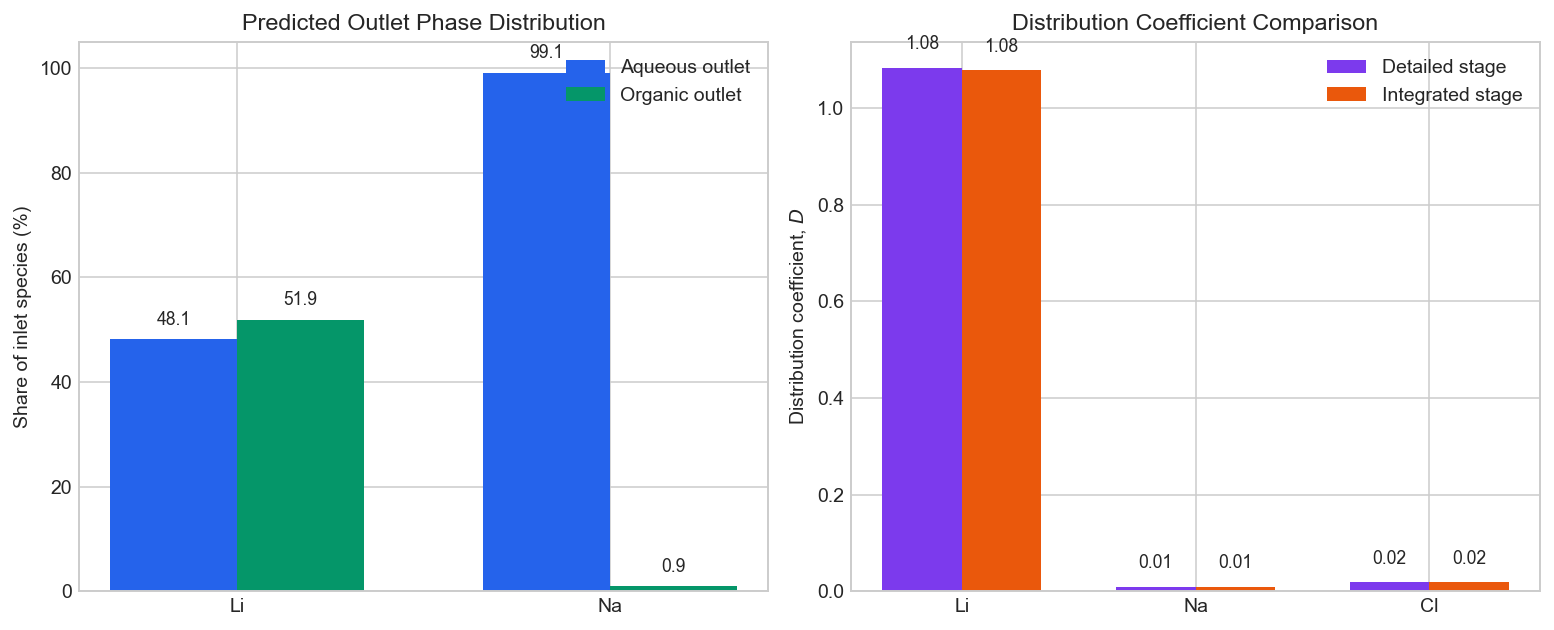

In [10]:

aq_in = model.fs.solex.mscontactor.aqueous_inlet_state[0]
aq_out = model.fs.solex.mscontactor.aqueous[0, stage]
og_out = model.fs.solex.mscontactor.organic[0, stage]

species_focus = ['Li', 'Na']
phase_split_rows = []
for species in species_focus:
    inlet_mass = value(aq_in.conc_mass_comp[species] * aq_in.flow_vol)
    aq_mass = value(aq_out.conc_mass_comp[species] * aq_out.flow_vol)
    og_mass = value(og_out.conc_mass_comp[species] * og_out.flow_vol)
    phase_split_rows.append(
        {
            'Species': species,
            'Aqueous outlet share (%)': 100.0 * aq_mass / max(inlet_mass, 1e-8),
            'Organic outlet share (%)': 100.0 * og_mass / max(inlet_mass, 1e-8),
        }
    )
phase_split_df = pd.DataFrame(phase_split_rows)

coeff_plot_df = pd.DataFrame(
    {
        'Species': ['Li', 'Na', 'Cl'],
        'Detailed stage D': [chemistry_distribution['D_li'], chemistry_distribution['D_na'], chemistry_distribution['D_cl']],
        'Integrated PrOMMiS D': [value(model.fs.D_li), value(model.fs.D_na), value(model.fs.D_cl)],
    }
)

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6))

x = np.arange(len(phase_split_df))
width = 0.34
axes[0].bar(x - width / 2, phase_split_df['Aqueous outlet share (%)'], width=width, color='#2563eb', label='Aqueous outlet')
axes[0].bar(x + width / 2, phase_split_df['Organic outlet share (%)'], width=width, color='#059669', label='Organic outlet')
axes[0].set_xticks(x)
axes[0].set_xticklabels(phase_split_df['Species'])
axes[0].set_ylabel('Share of inlet species (%)')
axes[0].set_title('Predicted Outlet Phase Distribution')
axes[0].set_ylim(0, 105)
axes[0].legend(frameon=False, loc='upper right')
for idx, row in phase_split_df.iterrows():
    axes[0].text(idx - width / 2, row['Aqueous outlet share (%)'] + 2.0, f"{row['Aqueous outlet share (%)']:.1f}", ha='center', va='bottom', fontsize=9)
    axes[0].text(idx + width / 2, row['Organic outlet share (%)'] + 2.0, f"{row['Organic outlet share (%)']:.1f}", ha='center', va='bottom', fontsize=9)

x2 = np.arange(len(coeff_plot_df))
axes[1].bar(x2 - width / 2, coeff_plot_df['Detailed stage D'], width=width, color='#7c3aed', label='Detailed stage')
axes[1].bar(x2 + width / 2, coeff_plot_df['Integrated PrOMMiS D'], width=width, color='#ea580c', label='Integrated stage')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(coeff_plot_df['Species'])
axes[1].set_ylabel('Distribution coefficient, $D$')
axes[1].set_title('Distribution Coefficient Comparison')
axes[1].legend(frameon=False, loc='upper right')
for idx, row in coeff_plot_df.iterrows():
    axes[1].text(idx - width / 2, row['Detailed stage D'] + 0.03, f"{row['Detailed stage D']:.2f}", ha='center', va='bottom', fontsize=9)
    axes[1].text(idx + width / 2, row['Integrated PrOMMiS D'] + 0.03, f"{row['Integrated PrOMMiS D']:.2f}", ha='center', va='bottom', fontsize=9)

fig.tight_layout()
plt.show()



## 11. What This Notebook Shows

This notebook demonstrates a complete surrogate workflow for detailed stage integration:

1. choose a case-study operating window,
2. sample the stage-response generator over that window,
3. fit a multi-output algebraic surrogate for the distribution coefficients, and
4. embed those surrogate equations directly inside a `PrOMMiS` solvent extraction model.

The final `PrOMMiS` solve uses the surrogate-generated distribution coefficients together with the stage mass balances to determine outlet compositions and phase split behavior. That is the key idea behind using this workflow inside a larger optimization or flowsheet study.
